# Self-Learning Lab Program 3 (Continuous Evaluation)
## Residual CNNs, Batch Normalization & Augmentation · Transfer Learning with a Pretrained Lightweight CNN · Feature Maps and Grad-CAM

**Framework:** PyTorch + torchvision | **Runtime:** Colab → *Runtime ▸ Change runtime type ▸ T4 GPU* (a GPU is strongly recommended; total run time ≈ 25–40 min on a T4)

### Objectives
1. Implement **residual connections** and compare **plain vs. residual CNNs** on CIFAR-10.
2. Apply **data augmentation** and **batch normalization**, and measure each one's contribution.
3. Using a **pretrained lightweight CNN (MobileNetV2)**, compare **frozen feature extraction** with **partial fine-tuning** on a CIFAR-10 subset.
4. **Visualize feature maps** and **Grad-CAM explanations**.

### Structure
| Part | Content |
|---|---|
| A | Plain vs. residual CNNs; batch-norm and augmentation ablations (trained from scratch) |
| B | Transfer learning: frozen extractor vs. partial fine-tuning (MobileNetV2) |
| C | Feature-map visualisation and Grad-CAM |
| D | Summary |

> **Controlled-experiment rule:** each comparison changes *one* factor; seed, data subset, optimizer, schedule, batch size and epochs are otherwise identical.

## 0. Setup & Data

In [ ]:
import time, math, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets, models

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = device.type == 'cuda'                      # mixed precision speeds up training on GPU
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Device:', device, '| AMP:', AMP, '| torch', torch.__version__)

Device: cuda | AMP: True | torch 2.14.1+cu130


**Data subsets.** To keep experiments fast, we use a **subset of CIFAR-10**: 10,000 training images for Part A (5,000 for the pretrained model in Part B), a fixed 2,000-image validation set, and the official 10,000-image test set (used only for the final numbers). Images are kept as `[0,1]` float tensors on the GPU; each model normalises internally (CIFAR statistics for from-scratch nets, ImageNet statistics for the pretrained net).

In [ ]:
tr_set = datasets.CIFAR10('./data', train=True,  download=True)
te_set = datasets.CIFAR10('./data', train=False, download=True)
CLASSES = tr_set.classes

def to_t(ds):
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float().div(255.)      # (N,3,32,32) in [0,1]
    return x, torch.tensor(ds.targets)

X_all, y_all = to_t(tr_set); X_te_all, y_te_all = to_t(te_set)
g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(X_all), generator=g)
N_TRAIN, N_VAL = 10000, 2000
X_tr, y_tr = X_all[perm[:N_TRAIN]].to(device), y_all[perm[:N_TRAIN]].to(device)
X_va, y_va = X_all[perm[N_TRAIN:N_TRAIN + N_VAL]].to(device), y_all[perm[N_TRAIN:N_TRAIN + N_VAL]].to(device)
X_te, y_te = X_te_all.to(device), y_te_all.to(device)
print('train', tuple(X_tr.shape), '| val', tuple(X_va.shape), '| test', tuple(X_te.shape))
print('class counts in train subset:', torch.bincount(y_tr.cpu()).tolist())

CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1)); self.register_buffer('std', torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x): return (x - self.mean) / self.std

100%|██████████| 170M/170M [24:27<00:00, 116kB/s]


train (10000, 3, 32, 32) | val (2000, 3, 32, 32) | test (10000, 3, 32, 32)
class counts in train subset: [1024, 996, 983, 990, 995, 981, 1029, 1022, 980, 1000]


## 0.1 Shared utilities: augmentation, training loop, evaluation
**Data augmentation** creates new, label-preserving variants of each training image *on the fly*, which acts as a regulariser. We use the standard CIFAR recipe: **random crop** (reflect-pad 4 px, crop back to 32×32) + **random horizontal flip**, implemented per-sample on the GPU. Augmentation is applied **only to training batches**.

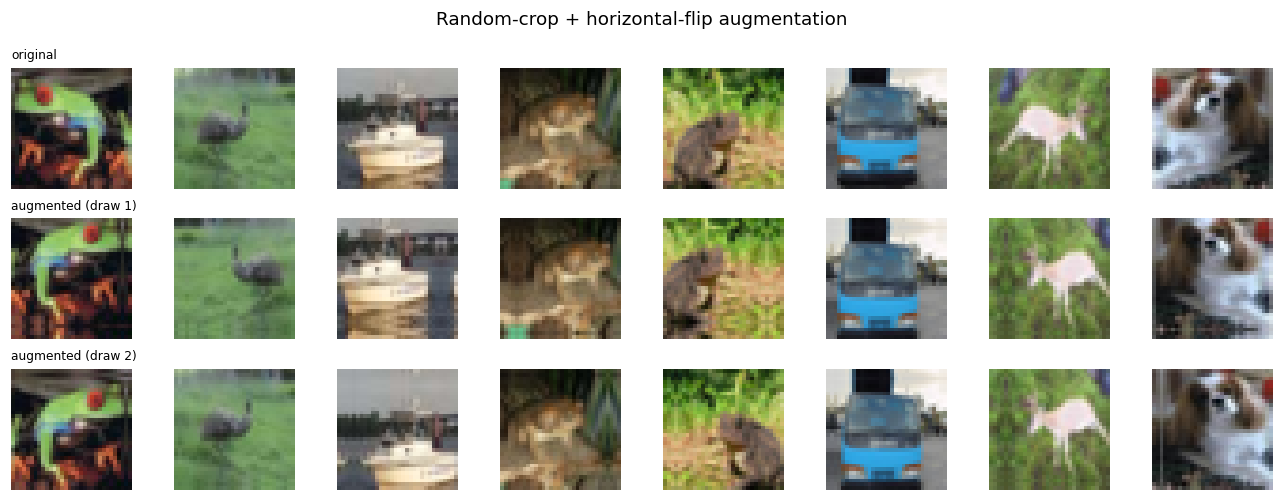

In [ ]:
def augment_batch(xb, pad=4):
    B, C, H, W = xb.shape; dev = xb.device
    xp = F.pad(xb, (pad,) * 4, mode='reflect')
    i = torch.randint(0, 2 * pad + 1, (B,), device=dev); j = torch.randint(0, 2 * pad + 1, (B,), device=dev)
    rows = (i[:, None] + torch.arange(H, device=dev)[None])          # (B,H)
    cols = (j[:, None] + torch.arange(W, device=dev)[None])          # (B,W)
    out = xp[torch.arange(B, device=dev)[:, None, None, None], torch.arange(C, device=dev)[None, :, None, None],
             rows[:, None, :, None], cols[:, None, None, :]]
    flip = torch.rand(B, device=dev) < 0.5
    return torch.where(flip[:, None, None, None], out.flip(3), out)

set_seed(1)
xb = X_tr[:8]; xa = augment_batch(xb)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.6))
for k in range(8):
    axes[0, k].imshow(xb[k].permute(1, 2, 0).cpu()); axes[1, k].imshow(xa[k].permute(1, 2, 0).cpu())
    axes[2, k].imshow(augment_batch(xb[k:k + 1])[0].permute(1, 2, 0).cpu())
    for r in range(3): axes[r, k].axis('off')
axes[0, 0].set_title('original', fontsize=8, loc='left'); axes[1, 0].set_title('augmented (draw 1)', fontsize=8, loc='left'); axes[2, 0].set_title('augmented (draw 2)', fontsize=8, loc='left')
plt.suptitle('Random-crop + horizontal-flip augmentation'); plt.tight_layout(); plt.show()

In [ ]:
@torch.no_grad()
def evaluate(model, X, y, bs=500):
    model.eval(); loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP):
            out = model(X[i:i + bs])
        loss += F.cross_entropy(out.float(), y[i:i + bs], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def fit(model, opt, X, y, epochs, bs=128, augment=True, sched=None, sched_per_batch=False, clip=5.0, seed=0, verbose=False):
    keys = ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']
    hist = {k: [] for k in keys}; hist['diverged'] = False
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    params = [p for g_ in opt.param_groups for p in g_['params']]
    gen = torch.Generator().manual_seed(seed); n, t0 = len(X), time.time()
    for ep in range(epochs):
        model.train(); order = torch.randperm(n, generator=gen).to(device)
        run_loss = torch.zeros((), device=device); run_correct = torch.zeros((), device=device)
        for i in range(0, n, bs):
            idx = order[i:i + bs]; xb, yb = X[idx], y[idx]
            if augment: xb = augment_batch(xb)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP):
                out = model(xb); loss = F.cross_entropy(out.float(), yb)
            scaler.scale(loss).backward()
            if clip: scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, clip)
            scaler.step(opt); scaler.update()
            if sched is not None and sched_per_batch: sched.step()
            run_loss += loss.detach() * len(idx); run_correct += (out.argmax(1) == yb).sum()
        if sched is not None and not sched_per_batch: sched.step()
        tl, ta = run_loss.item() / n, run_correct.item() / n
        if not math.isfinite(tl):
            hist['diverged'] = True
            if verbose: print(f'epoch {ep + 1}: loss is NaN/inf -> training diverged, stopping')
            break
        vl, va = evaluate(model, X_va, y_va)
        for k, v in zip(keys, [tl, ta, vl, va, time.time() - t0]): hist[k].append(v)
        if verbose: print(f'epoch {ep + 1:2d}/{epochs} | train {tl:.3f}/{ta:.3f} | val {vl:.3f}/{va:.3f} | {time.time() - t0:5.1f}s')
    return hist

def plot_hist(runs, keys=('train_loss', 'val_loss', 'val_acc'), figsize=None):
    fig, axes = plt.subplots(1, len(keys), figsize=figsize or (5.2 * len(keys), 4))
    for ax, k in zip(np.atleast_1d(axes), keys):
        for r in runs: ax.plot(range(1, len(r[k]) + 1), r[k], label=r['name'], marker='o' if len(r[k]) == 1 else None)
        ax.set_title(k.replace('_', ' ').title()); ax.set_xlabel('Epoch')
    np.atleast_1d(axes)[0].legend(fontsize=7); plt.tight_layout(); plt.show()

def summarize(runs):
    rows = [{'Run': r['name'], 'Params': r['params'], 'Trainable': r.get('trainable', r['params']),
             'Val acc': (r['val_acc'][-1] if r['val_acc'] else float('nan')), 'Best val': (max(r['val_acc']) if r['val_acc'] else float('nan')),
             'Test acc': r['test_acc'], 'Time (s)': (r['time'][-1] if r['time'] else float('nan')), 'Diverged': r['diverged']} for r in runs]
    return pd.DataFrame(rows).set_index('Run').round(4)
print('utilities ready')

utilities ready


# Part A: Plain vs. Residual CNNs (with Batch Normalization and Augmentation)

## A.1 Residual connections
Very deep plain networks are hard to optimise: gradients shrink (or explode) as they travel back through many layers, and accuracy can even *decrease* with depth (the **degradation problem**, He et al. 2015). A **residual block** adds a **skip (identity) connection**:

$$ y = \mathrm{ReLU}\big(\mathcal{F}(x) + x\big), \qquad \mathcal{F}(x) = \mathrm{BN}(\mathrm{Conv}(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x))))) $$

The block only has to learn a **residual** $\mathcal{F}(x)=y-x$, and during back-propagation the gradient has a direct path: $\partial y/\partial x = \partial\mathcal{F}/\partial x + I$.

When the block changes the number of channels or the resolution, the skip must match shapes. We use the parameter-free **"option A" shortcut** (sub-sample spatially with stride 2 and zero-pad the extra channels), so a plain and a residual network have **exactly the same number of parameters**, and the only difference is the skip connection.

## A.2 Batch normalization
For each channel, BN standardises activations over the mini-batch and then rescales with learnable $\gamma,\beta$:

$$ \hat x = \frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}, \qquad y=\gamma\hat x+\beta $$

It stabilises activation scales, allows larger learning rates, speeds up convergence and has a mild regularising effect (batch noise). At inference, running averages of $\mu,\sigma^2$ are used (hence `model.eval()` matters!).

## A.3 Architecture
CIFAR-style ResNet with $6n+2$ weighted layers: 3×3 stem (16 ch) → 3 stages of $n$ blocks with 16/32/64 channels (stride 2 at the start of stages 2 and 3) → global average pooling → linear layer. `kind='plain'` removes the skip; `bn=False` removes batch-norm.

In [ ]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual, bn):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=not bn); self.bn1 = nn.BatchNorm2d(cout) if bn else nn.Identity()
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=not bn);     self.bn2 = nn.BatchNorm2d(cout) if bn else nn.Identity()
        self.residual, self.stride, self.pad = residual, stride, (cout - cin) // 2
    def shortcut(self, x):                                   # parameter-free "option A" shortcut
        if self.stride != 1 or self.pad:
            x = x[:, :, ::self.stride, ::self.stride]
            x = F.pad(x, (0, 0, 0, 0, self.pad, self.pad))   # zero-pad the channel dimension
        return x
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual: out = out + self.shortcut(x)
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, kind='res', n=3, bn=True, widths=(16, 32, 64)):
        super().__init__()
        residual = (kind == 'res')
        self.norm = Normalize(CIFAR_MEAN, CIFAR_STD)
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=not bn), nn.BatchNorm2d(widths[0]) if bn else nn.Identity(), nn.ReLU())
        stages, cin = [], widths[0]
        for si, w in enumerate(widths):
            stages.append(nn.Sequential(*[Block(cin if b == 0 else w, w, 2 if (si > 0 and b == 0) else 1, residual, bn) for b in range(n)]))
            cin = w
        self.stages = nn.Sequential(*stages)
        self.fc = nn.Linear(widths[-1], 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(self, x):
        x = self.stages(self.stem(self.norm(x)))
        return self.fc(x.mean((2, 3)))

count = lambda m: sum(p.numel() for p in m.parameters())
for n in (2, 6):
    p, r = CifarNet('plain', n), CifarNet('res', n)
    print(f'n={n} -> {6 * n + 2} layers | plain params = {count(p):,} | residual params = {count(r):,}')
x = torch.rand(2, 3, 32, 32); print('output shape:', tuple(CifarNet('res', 2)(x).shape))

n=2 -> 14 layers | plain params = 172,506 | residual params = 172,506
n=6 -> 38 layers | plain params = 561,370 | residual params = 561,370
output shape: (2, 10)


## A.4 Why skips help: gradient flow at initialisation
Before training, we back-propagate one batch through a **deep** plain and a **deep** residual network and record the **gradient norm of every convolution layer**. Vanishing/exploding gradients show up as a large spread across depth.

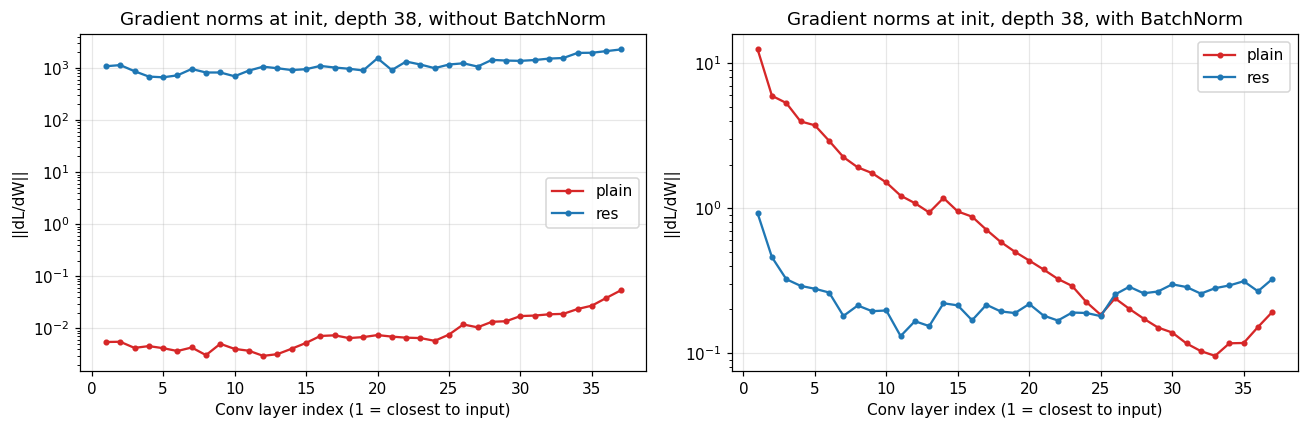

In [ ]:
N_SHALLOW, N_DEEP = 2, 6          # 14 and 38 layers (increase N_DEEP, e.g. 9 -> 56 layers, for a more dramatic effect)

def layer_grad_norms(kind, n, bn):
    set_seed(0); m = CifarNet(kind, n, bn).to(device).train()
    out = m(X_tr[:256]); F.cross_entropy(out, y_tr[:256]).backward()
    return [c.weight.grad.norm().item() for c in m.modules() if isinstance(c, nn.Conv2d)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, bn in zip(axes, [False, True]):
    for kind, c in [('plain', 'tab:red'), ('res', 'tab:blue')]:
        gn = layer_grad_norms(kind, N_DEEP, bn); ax.plot(range(1, len(gn) + 1), gn, marker='o', ms=3, color=c, label=kind)
    ax.set_yscale('log'); ax.set_xlabel('Conv layer index (1 = closest to input)'); ax.set_ylabel('||dL/dW||')
    ax.set_title(f'Gradient norms at init, depth {6 * N_DEEP + 2}, {"with" if bn else "without"} BatchNorm'); ax.legend()
plt.tight_layout(); plt.show()

## A.5 Training protocol (identical for all runs)
SGD + Nesterov momentum (0.9), weight decay 5e-4, one-cycle learning-rate schedule (max lr 0.05; includes warm-up), batch size 128, **15 epochs**, gradient-norm clipping 5.0, seed 0, mixed precision on GPU.

Experiments
1. **Plain vs. residual** at shallow (14-layer) and deep (38-layer) depth, with BN + augmentation.
2. **Batch-norm ablation:** deep plain and residual nets *without* BN.
3. **Augmentation ablation:** deep residual net *without* augmentation.

In [ ]:
EPOCHS, BS, LR = 15, 128, 0.05
trained = {}

def run_scratch(name, kind, n, bn=True, augment=True, epochs=EPOCHS, seed=0, keep=False):
    set_seed(seed); model = CifarNet(kind, n, bn).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * math.ceil(N_TRAIN / BS))
    h = fit(model, opt, X_tr, y_tr, epochs, BS, augment, sched, sched_per_batch=True, seed=seed)
    h['test_loss'], h['test_acc'] = evaluate(model, X_te, y_te)
    h['name'], h['params'] = name, count(model)
    if keep: trained[name] = model
    print(f"{name:42s} val acc {h['val_acc'][-1] if h['val_acc'] else float('nan'):.3f} | test acc {h['test_acc']:.3f} | {h['time'][-1] if h['time'] else 0:.0f}s" + ('  [DIVERGED]' if h['diverged'] else ''))
    return h

L_S, L_D = 6 * N_SHALLOW + 2, 6 * N_DEEP + 2
exp1 = [run_scratch(f'Plain-{L_S} (BN, aug)',    'plain', N_SHALLOW),
        run_scratch(f'Residual-{L_S} (BN, aug)', 'res',   N_SHALLOW),
        run_scratch(f'Plain-{L_D} (BN, aug)',    'plain', N_DEEP, keep=True),
        run_scratch(f'Residual-{L_D} (BN, aug)', 'res',   N_DEEP, keep=True)]
summarize(exp1)

Plain-14 (BN, aug)                         val acc 0.705 | test acc 0.698 | 14s
Residual-14 (BN, aug)                      val acc 0.709 | test acc 0.707 | 15s


/tmp/ipykernel_517/3486301215.py:29: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched is not None and sched_per_batch: sched.step()


Plain-38 (BN, aug)                         val acc 0.528 | test acc 0.512 | 34s
Residual-38 (BN, aug)                      val acc 0.740 | test acc 0.727 | 37s


,Params,Trainable,Val acc,Best val,Test acc,Time (s),Diverged
Run,,,,,,,
"Plain-14 (BN, aug)",172506,172506,0.7050,0.7050,0.6978,14.3503,False
"Residual-14 (BN, aug)",172506,172506,0.7090,0.7115,0.7067,14.9306,False
"Plain-38 (BN, aug)",561370,561370,0.5285,0.5285,0.5116,34.4409,False
"Residual-38 (BN, aug)",561370,561370,0.7400,0.7420,0.7270,36.9997,False


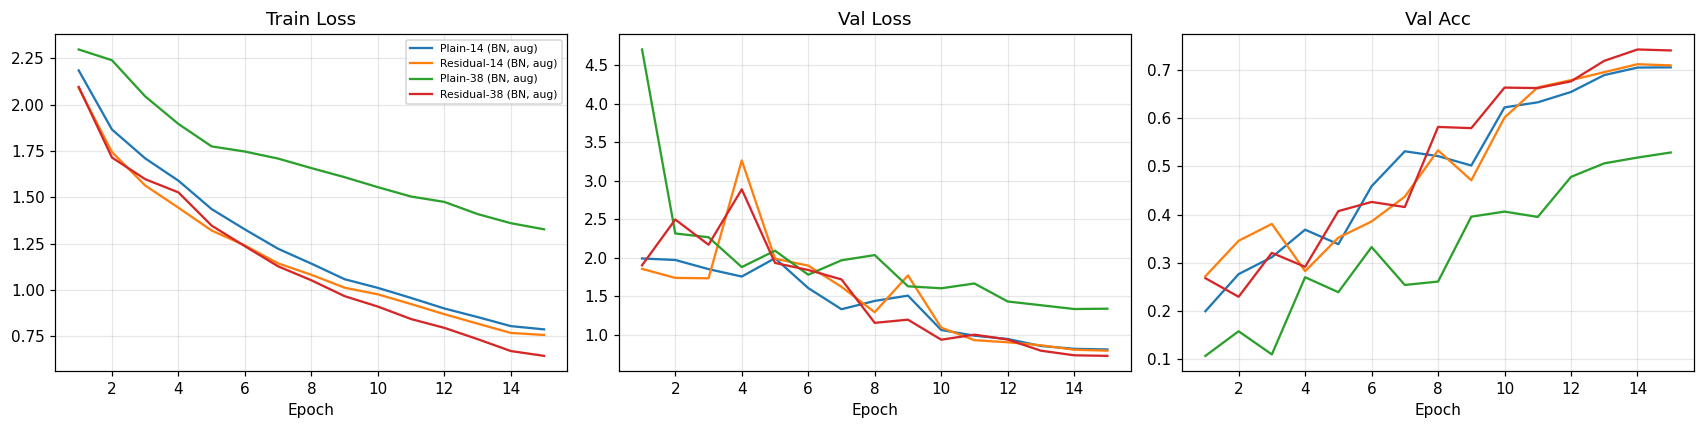

In [ ]:
plot_hist(exp1, keys=('train_loss', 'val_loss', 'val_acc'))

In [ ]:
# Experiment 2: batch-norm ablation (deep nets)   |   Experiment 3: augmentation ablation (deep residual)
exp2 = [run_scratch(f'Plain-{L_D} (no BN, aug)',    'plain', N_DEEP, bn=False),
        run_scratch(f'Residual-{L_D} (no BN, aug)', 'res',   N_DEEP, bn=False)]
exp3 = [run_scratch(f'Residual-{L_D} (BN, NO aug)', 'res',   N_DEEP, augment=False)]

display(summarize(exp2 + exp3))

Plain-38 (no BN, aug)                      val acc 0.182 | test acc 0.182 | 28s


/tmp/ipykernel_517/3486301215.py:29: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched is not None and sched_per_batch: sched.step()


Residual-38 (no BN, aug)                   val acc 0.564 | test acc 0.566 | 30s
Residual-38 (BN, NO aug)                   val acc 0.688 | test acc 0.656 | 37s


,Params,Trainable,Val acc,Best val,Test acc,Time (s),Diverged
Run,,,,,,,
"Plain-38 (no BN, aug)",560010,560010,0.1825,0.1915,0.1824,28.3723,False
"Residual-38 (no BN, aug)",560010,560010,0.5635,0.5635,0.5661,30.2510,False
"Residual-38 (BN, NO aug)",561370,561370,0.6880,0.6880,0.6565,37.1707,False


,Params,Val acc,Test acc,Time (s),Diverged
Run,,,,,
"Plain-14 (BN, aug)",172506,0.7050,0.6978,14.3503,False
"Residual-14 (BN, aug)",172506,0.7090,0.7067,14.9306,False
"Plain-38 (BN, aug)",561370,0.5285,0.5116,34.4409,False
"Residual-38 (BN, aug)",561370,0.7400,0.7270,36.9997,False
"Plain-38 (no BN, aug)",560010,0.1825,0.1824,28.3723,False
"Residual-38 (no BN, aug)",560010,0.5635,0.5661,30.2510,False
"Residual-38 (BN, NO aug)",561370,0.6880,0.6565,37.1707,False


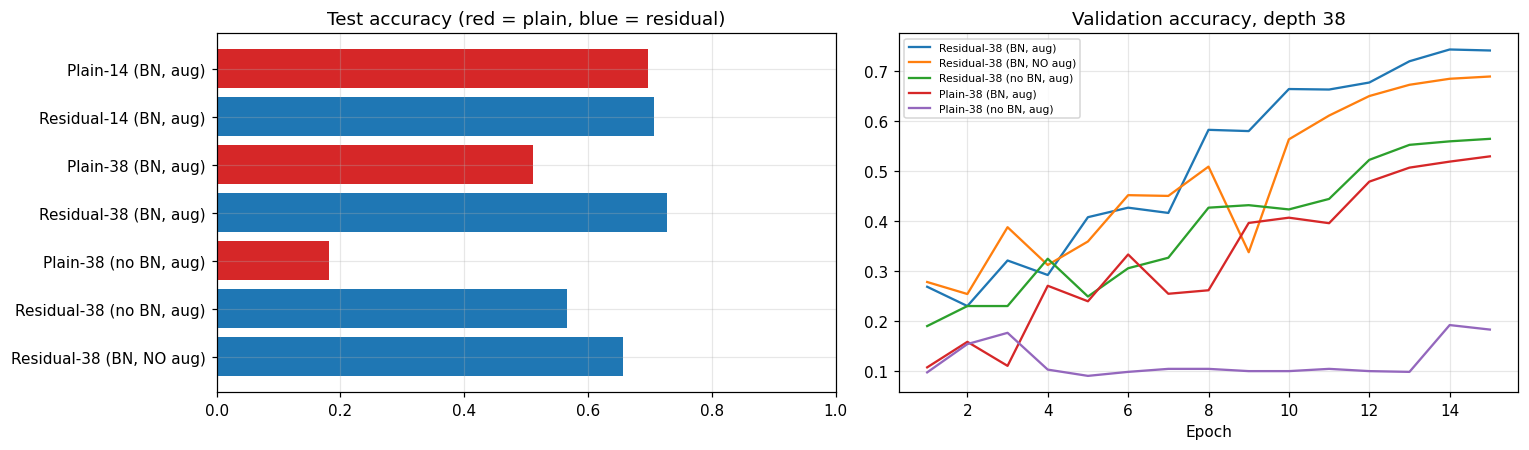

In [ ]:
# Combined comparison: baseline deep runs + ablations
all_runs = exp1 + exp2 + exp3
tab = summarize(all_runs)
display(tab[['Params', 'Val acc', 'Test acc', 'Time (s)', 'Diverged']])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].barh(tab.index, tab['Test acc'], color=['tab:red' if 'Plain' in i else 'tab:blue' for i in tab.index]); ax[0].invert_yaxis()
ax[0].set_title('Test accuracy (red = plain, blue = residual)'); ax[0].set_xlim(0, 1)
plot_hist_runs = [exp1[3], exp3[0], exp2[1], exp1[2], exp2[0]]
for r in plot_hist_runs: ax[1].plot(range(1, len(r['val_acc']) + 1), r['val_acc'], label=r['name'])
ax[1].set_title(f'Validation accuracy, depth {L_D}'); ax[1].set_xlabel('Epoch'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Observations (Part A)
*Verify against your own tables/plots. Typical outcomes:*
* **Depth, plain:** the deep plain net is no better (often worse or slower to train) than the shallow plain net, which is the degradation problem; the gradient plot shows larger spread across depth.
* **Residual:** the residual net trains faster and gains from depth; at equal parameter count it usually beats the plain net, with the gap larger for the deep model.
* **BatchNorm:** removing BN hurts a lot for deep nets (slow, unstable or divergent training at this learning rate). Skips alone do not fully replace normalisation, and BN alone does not remove the plain-net degradation, so they are complementary.
* **Augmentation:** without augmentation the train–val gap is larger (overfitting on a 10k subset), and validation accuracy is lower. Training accuracy shown for augmented runs is measured on augmented batches, so it can look *lower* than the non-augmented run even when generalisation is better.
* Single-seed differences of ≲1 % are within noise.

# Part B: Transfer Learning with a Pretrained Lightweight CNN
## B.1 Idea
Features learned on a large dataset (ImageNet, 1.2 M images) transfer to new tasks: early layers detect generic edges/colours/textures, later layers detect task-specific parts. With only a small dataset, reusing them beats training from scratch. Two common strategies:

| Strategy | What is trained | Cost / risk |
|---|---|---|
| **Frozen feature extraction** | only a new linear classifier on top of fixed features | fastest, very few parameters, cannot adapt features to CIFAR-10 |
| **Partial fine-tuning** | the new head **plus the last *k* blocks** of the backbone (with a smaller LR); earlier layers stay frozen | adapts high-level features; more parameters, risk of overfitting / forgetting if LR is too high |

**Model:** **MobileNetV2** (3.4 M parameters, ImageNet-pretrained; built from inverted-residual blocks with depthwise separable convolutions, so it is lightweight and suited for mobile devices). CIFAR images are 32×32 while the network was trained at 224×224, so we **up-sample inputs to 128×128** inside the model.

**Details:** frozen layers keep their BatchNorm layers in **eval mode** (running statistics are not updated); backbone parameters use a 10× smaller learning rate (1e-4) than the new head (1e-3); optimizer AdamW; cosine decay; 8 epochs; augmentation on; **5,000-image training subset**.

In [ ]:
IMG, N_TF, EPOCHS_TF = 128, 5000, 8
X_tf, y_tf = X_tr[:N_TF], y_tr[:N_TF]

class TransferNet(nn.Module):
    def __init__(self, pretrained=True, unfreeze_from=None, img=IMG, dropout=0.2):
        super().__init__()
        w = models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        self.features = models.mobilenet_v2(weights=w).features         # 19 modules: features[0] ... features[18]
        self.norm, self.img = Normalize(IMNET_MEAN, IMNET_STD), img
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(1280, 10))
        self.set_trainable(unfreeze_from)
    def set_trainable(self, k):
        # k=None: whole backbone frozen | k=0: everything trainable | k=int: features[k:] trainable
        self.k = len(self.features) if k is None else k
        for i, m in enumerate(self.features):
            for p in m.parameters(): p.requires_grad = i >= self.k
        self.train()
    def train(self, mode=True):
        super().train(mode)
        for i, m in enumerate(self.features):
            if i < self.k: m.eval()                                     # frozen blocks keep BN statistics fixed
        return self
    def forward(self, x):
        x = F.interpolate(self.norm(x), size=(self.img, self.img), mode='bilinear', align_corners=False)
        f = F.adaptive_avg_pool2d(self.features(x), 1).flatten(1)
        return self.head(f)

m_ = TransferNet(unfreeze_from=None)
print('MobileNetV2 modules:', len(m_.features), '| total params:', f'{count(m_):,}')
for i in (0, 1, 7, 14, 17, 18): print(f'  features[{i:2d}]: {m_.features[i].__class__.__name__:22s} params = {sum(p.numel() for p in m_.features[i].parameters()):,}')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 155MB/s]

MobileNetV2 modules: 19 | total params: 2,236,682
  features[ 0]: Conv2dNormActivation   params = 928
  features[ 1]: InvertedResidual       params = 896
  features[ 7]: InvertedResidual       params = 21,056
  features[14]: InvertedResidual       params = 155,264
  features[17]: InvertedResidual       params = 473,920
  features[18]: Conv2dNormActivation   params = 412,160


## B.2 Experiments
| Run | Init | Trainable part |
|---|---|---|
| Scratch (reference) | random | everything |
| **Frozen extractor** | ImageNet | head only (12,810 params) |
| **Partial FT (last 2 blocks)** | ImageNet | `features[17:]` + head |
| **Partial FT (last 5 blocks)** | ImageNet | `features[14:]` + head |
| Full fine-tune (reference) | ImageNet | everything |

In [ ]:
trained_tf = {}
def run_tf(name, pretrained, unfreeze_from, seed=0, epochs=EPOCHS_TF, bs=64, head_lr=1e-3, bb_lr=1e-4):
    set_seed(seed); model = TransferNet(pretrained, unfreeze_from).to(device)
    groups = [{'params': model.head.parameters(), 'lr': head_lr}]
    bb = [p for p in model.features.parameters() if p.requires_grad]
    if bb: groups.append({'params': bb, 'lr': bb_lr if pretrained else head_lr})
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    h = fit(model, opt, X_tf, y_tf, epochs, bs, True, sched, clip=None, seed=seed)
    h['test_loss'], h['test_acc'] = evaluate(model, X_te, y_te)
    h['name'], h['params'] = name, count(model); h['trainable'] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    trained_tf[name] = model
    print(f"{name:34s} trainable {h['trainable']:>9,} | val {h['val_acc'][-1]:.3f} | test {h['test_acc']:.3f} | {h['time'][-1]:.0f}s")
    return h

tf_runs = [run_tf('Scratch (random init, all)',   False, 0),
           run_tf('Frozen extractor (head only)', True,  None),
           run_tf('Partial FT: last 2 blocks',    True,  17),
           run_tf('Partial FT: last 5 blocks',    True,  14),
           run_tf('Full fine-tune (all layers)',  True,  0)]
tf_tab = summarize(tf_runs)
tf_tab['% trainable'] = (100 * tf_tab['Trainable'] / tf_tab['Params']).round(1)
tf_tab['Sec/epoch'] = (tf_tab['Time (s)'] / EPOCHS_TF).round(1)
tf_tab[['Trainable', '% trainable', 'Val acc', 'Test acc', 'Time (s)', 'Sec/epoch']]

Scratch (random init, all)         trainable 2,236,682 | val 0.535 | test 0.537 | 37s
Frozen extractor (head only)       trainable    12,810 | val 0.831 | test 0.821 | 10s
Partial FT: last 2 blocks          trainable   898,890 | val 0.848 | test 0.838 | 12s
Partial FT: last 5 blocks          trainable 1,694,154 | val 0.878 | test 0.871 | 15s
Full fine-tune (all layers)        trainable 2,236,682 | val 0.899 | test 0.897 | 34s


,Trainable,% trainable,Val acc,Test acc,Time (s),Sec/epoch
Run,,,,,,
"Scratch (random init, all)",2236682,100.0,0.5355,0.5372,37.1895,4.6
Frozen extractor (head only),12810,0.6,0.8310,0.8207,10.3403,1.3
Partial FT: last 2 blocks,898890,40.2,0.8480,0.8381,12.1903,1.5
Partial FT: last 5 blocks,1694154,75.7,0.8780,0.8706,14.6812,1.8
Full fine-tune (all layers),2236682,100.0,0.8990,0.8972,33.8309,4.2


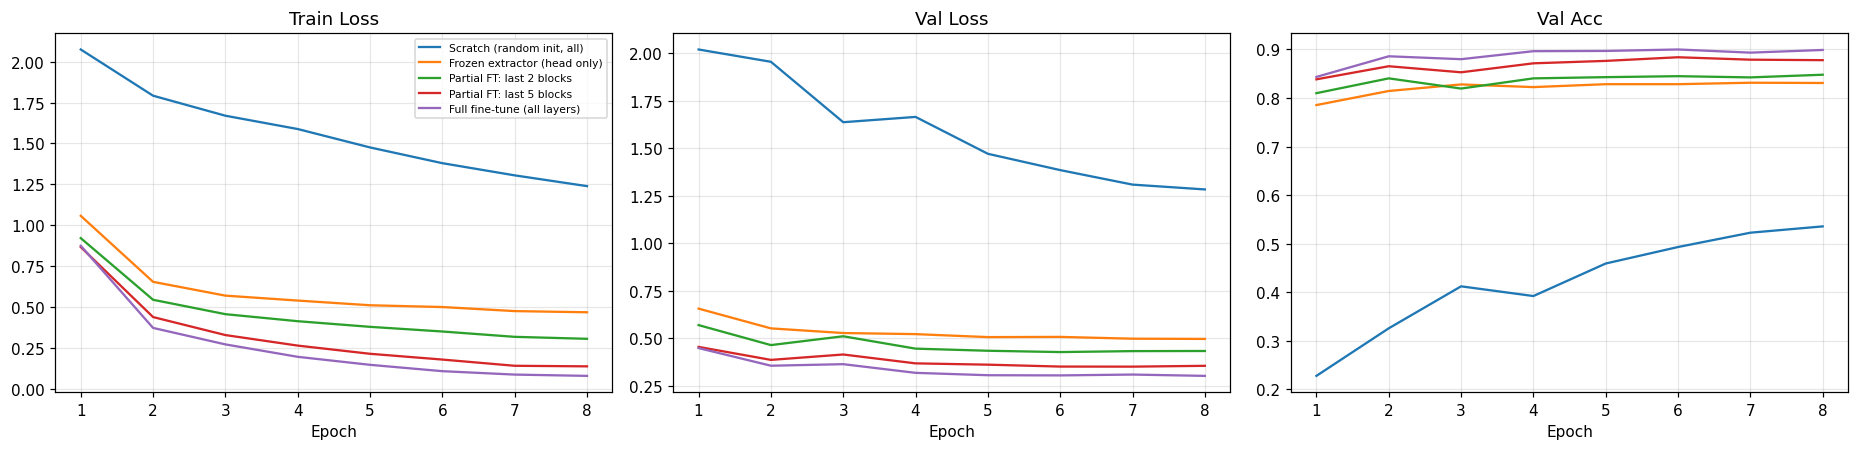

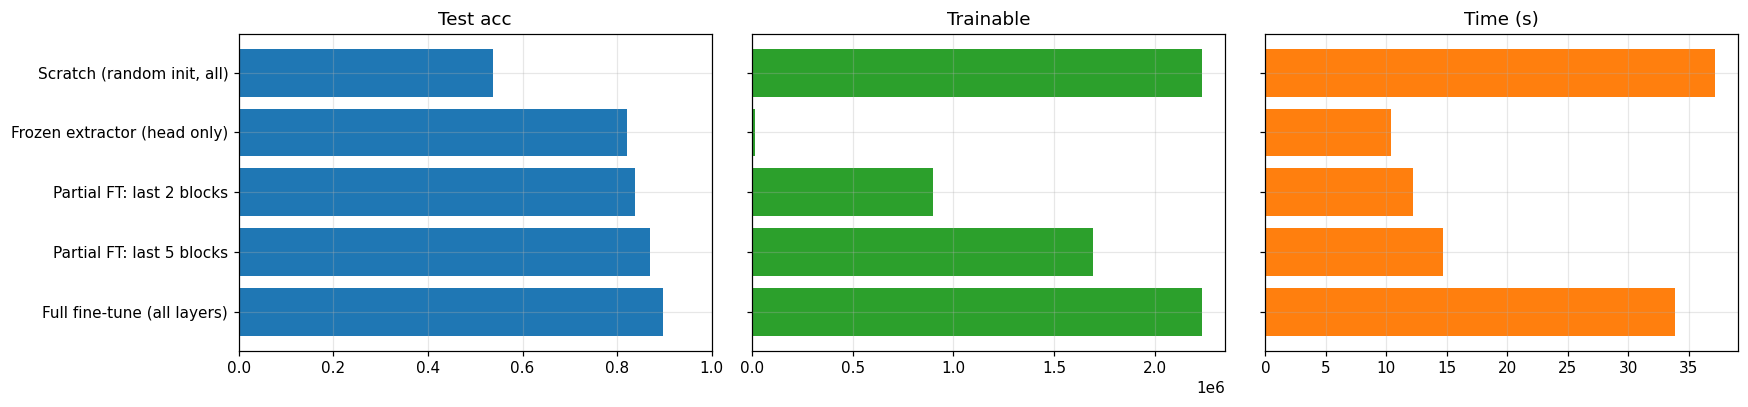

In [ ]:
plot_hist(tf_runs, keys=('train_loss', 'val_loss', 'val_acc'), figsize=(17, 4.2))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, c in zip(ax, ['Test acc', 'Trainable', 'Time (s)'], ['tab:blue', 'tab:green', 'tab:orange']):
    a.barh(tf_tab.index, tf_tab[col], color=c); a.invert_yaxis(); a.set_title(col)
    if col != 'Test acc': a.set_yticklabels([])
ax[0].set_xlim(0, 1); plt.tight_layout(); plt.show()

### Observations (Part B)
*Typical outcomes (verify with your numbers):*
* **Pretrained ≫ scratch** on 5,000 images: even a frozen extractor with a linear head usually beats the randomly initialised network trained on all layers.
* **Partial fine-tuning** (last 2–5 blocks) normally improves on the frozen extractor, because the high-level features adapt from ImageNet objects to the (up-sampled, low-resolution) CIFAR classes, at a modest increase in cost and trainable parameters.
* **Full fine-tuning** gives a small further gain or none, while being the most expensive and the most prone to overfitting/forgetting with little data.
* The frozen run is fastest per epoch (no backward pass through the backbone) and has only ≈ 12.8 k trainable parameters.

# Part C: Visualizing Feature Maps and Grad-CAM
## C.1 Feature maps
A feature map is the output of one convolutional filter at a given layer (a 2-D "detector response"). Inspecting maps at increasing depth shows the hierarchy: **early layers** respond to edges, colours and textures at high resolution; **deeper layers** produce low-resolution, more abstract, class-specific responses.

We use forward hooks to capture activations, first of our **from-scratch residual net** (Part A), then of the **pretrained MobileNetV2** and its first-layer filters.

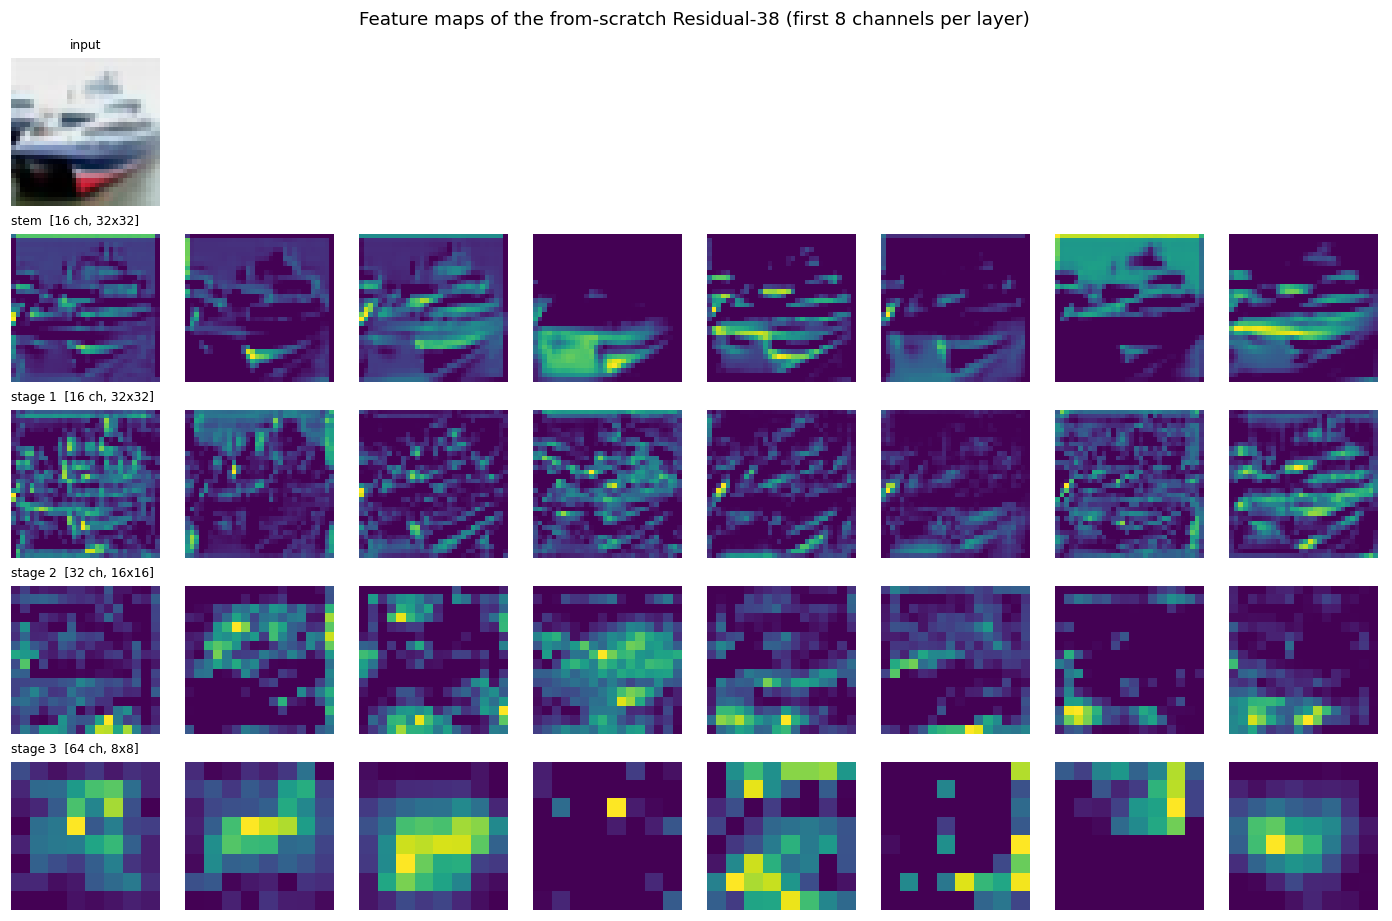

In [ ]:
def get_maps(model, x, layer):
    store = {}
    h = layer.register_forward_hook(lambda m, i, o: store.__setitem__('a', o.detach()))
    model.eval()
    with torch.no_grad(): model(x[None])
    h.remove(); return store['a'][0].float().cpu().numpy()                 # (C, h, w)

def show_feature_maps(model, x, layers, title, n=8):
    fig, axes = plt.subplots(len(layers) + 1, n, figsize=(1.6 * n, 1.7 * (len(layers) + 1)))
    axes[0, 0].imshow(x.permute(1, 2, 0).cpu()); axes[0, 0].set_title('input', fontsize=8)
    for a in axes[0]: a.axis('off')
    for r, (name, layer) in enumerate(layers.items(), start=1):
        fm = get_maps(model, x, layer)
        for c in range(n):
            axes[r, c].imshow(fm[c], cmap='viridis'); axes[r, c].axis('off')
        axes[r, 0].set_title(f'{name}  [{fm.shape[0]} ch, {fm.shape[1]}x{fm.shape[2]}]', fontsize=8, loc='left')
    plt.suptitle(title); plt.tight_layout(); plt.show()

res_model = trained[f'Residual-{L_D} (BN, aug)']
img_idx = int((y_te == CLASSES.index('ship')).nonzero()[0])
show_feature_maps(res_model, X_te[img_idx], {'stem': res_model.stem, 'stage 1': res_model.stages[0], 'stage 2': res_model.stages[1], 'stage 3': res_model.stages[2]},
                  f'Feature maps of the from-scratch Residual-{L_D} (first 8 channels per layer)')

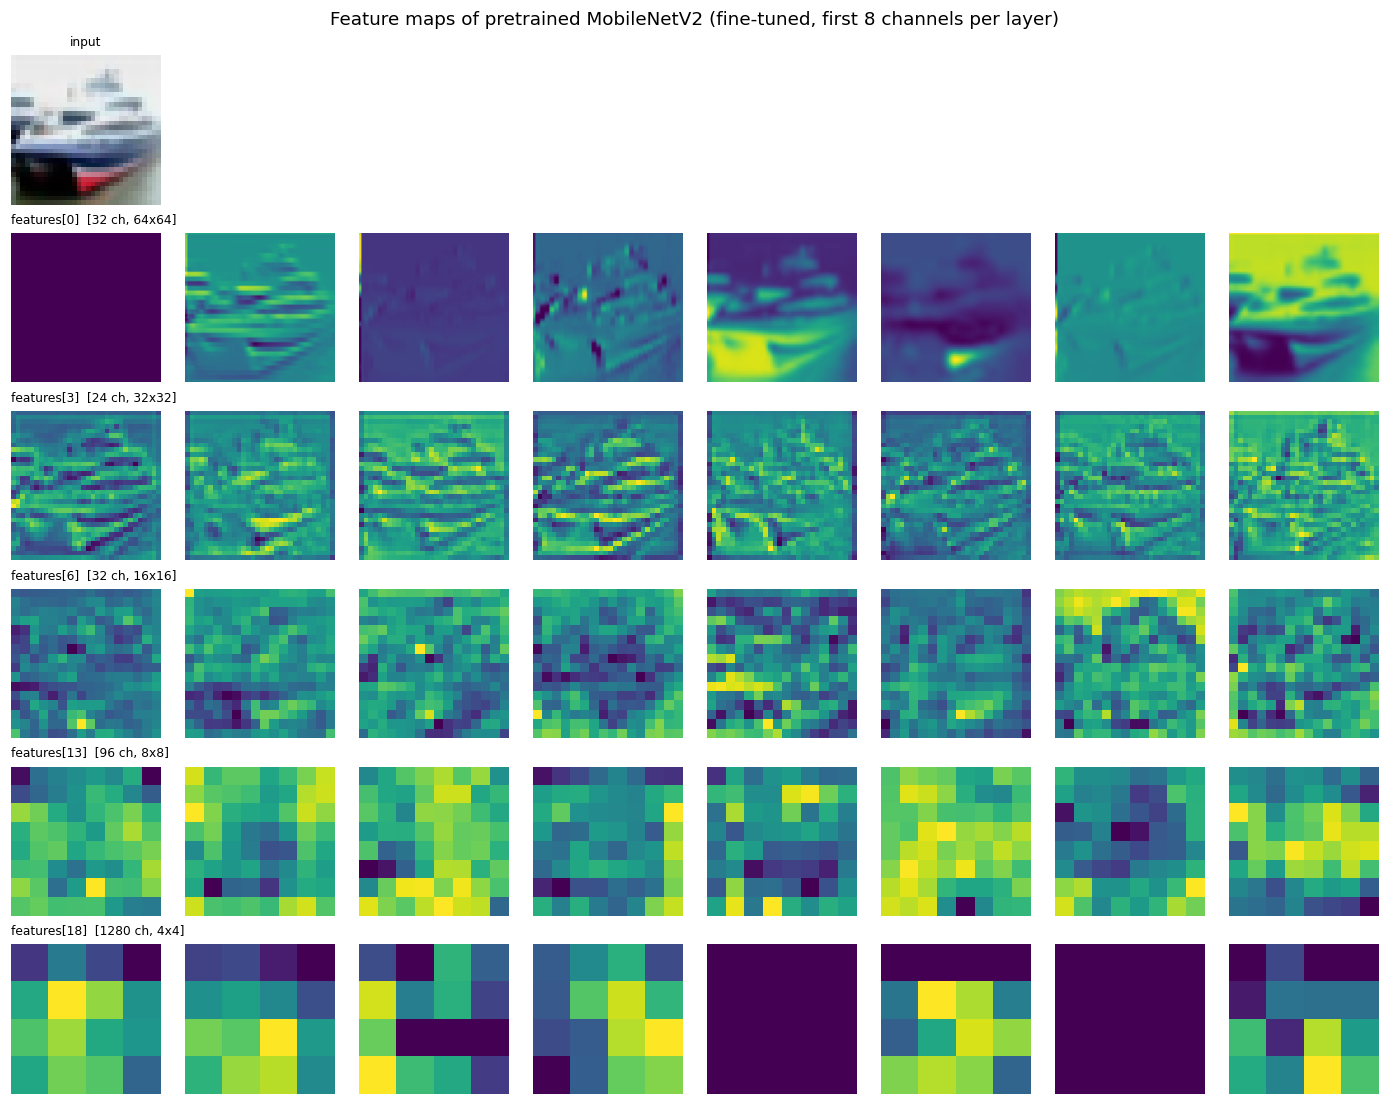

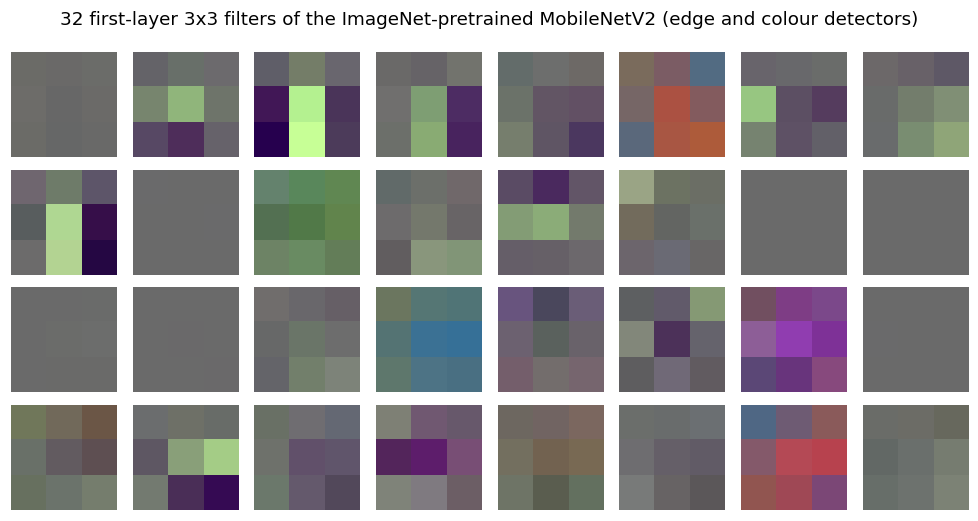

In [ ]:
ft_model = trained_tf['Partial FT: last 2 blocks']; fr_model = trained_tf['Frozen extractor (head only)']
show_feature_maps(ft_model, X_te[img_idx], {'features[0]': ft_model.features[0], 'features[3]': ft_model.features[3], 'features[6]': ft_model.features[6],
                                            'features[13]': ft_model.features[13], 'features[18]': ft_model.features[18]},
                  'Feature maps of pretrained MobileNetV2 (fine-tuned, first 8 channels per layer)')

# first-layer filters of the pretrained network
W = fr_model.features[0][0].weight.detach().cpu().numpy(); Wn = (W - W.min()) / (W.max() - W.min())
fig, axes = plt.subplots(4, 8, figsize=(9, 4.8))
for a, f in zip(axes.ravel(), range(W.shape[0])): a.imshow(Wn[f].transpose(1, 2, 0), interpolation='nearest'); a.axis('off')
plt.suptitle('32 first-layer 3x3 filters of the ImageNet-pretrained MobileNetV2 (edge and colour detectors)'); plt.tight_layout(); plt.show()

## C.2 Grad-CAM
**Grad-CAM** (Selvaraju et al., 2017) explains *where* a CNN looked for a particular class decision. For a target layer with feature maps $A^k$ and class score $y^c$:

1. Compute gradients $\partial y^c/\partial A^k$ by back-propagation.
2. Global-average-pool them to get a weight for each channel: $\alpha_k^c=\frac{1}{HW}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$.
3. Take the weighted sum of the maps and keep only positive evidence:

$$ L^c_{\text{Grad-CAM}}=\mathrm{ReLU}\Big(\sum_k \alpha_k^c A^k\Big) $$

4. Up-sample to the input size, normalise to [0,1] and overlay as a heat-map.

The resolution is that of the target layer (coarse for deep layers). We implement it from scratch using hooks, with the input set to `requires_grad=True` so gradients flow even through a frozen backbone.

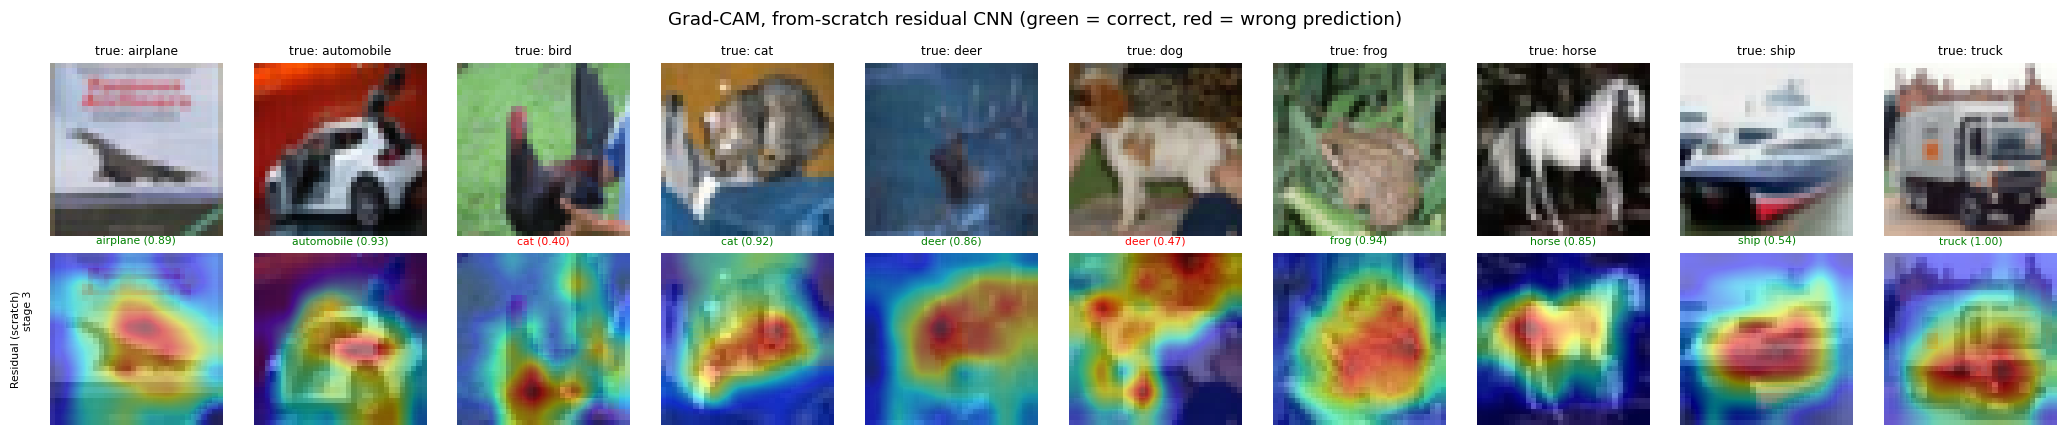

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out.detach()
        if out.requires_grad: out.register_hook(lambda g: setattr(self, 'grads', g.detach()))
    def __call__(self, x, class_idx=None):
        self.model.eval(); x = x.clone().requires_grad_(True)
        logits = self.model(x)
        if class_idx is None: class_idx = logits.argmax(1)
        score = logits.gather(1, class_idx[:, None]).sum()
        self.model.zero_grad(set_to_none=True); score.backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)                      # channel weights
        cam = F.relu((alpha * self.acts).sum(1, keepdim=True))                 # weighted combination + ReLU
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)
        cam = cam - cam.amin((2, 3), keepdim=True); cam = cam / (cam.amax((2, 3), keepdim=True) + 1e-8)
        return cam[:, 0].cpu().numpy(), logits.detach().softmax(1), class_idx
    def remove(self): self.handle.remove()

y_te_np = y_te.cpu().numpy()
def cam_figure(rows, X, idxs, title):
    # rows: {label: (model, target_layer)}; shows the image and one CAM row per entry
    idxs = list(idxs); n = len(idxs); fig, axes = plt.subplots(len(rows) + 1, n, figsize=(1.9 * n, 2.0 * (len(rows) + 1)))
    x = X[idxs]
    for k in range(n): axes[0, k].imshow(x[k].permute(1, 2, 0).cpu()); axes[0, k].set_title(f'true: {CLASSES[y_te_np[idxs[k]]]}', fontsize=8); axes[0, k].axis('off')
    for r, (label, (model, layer)) in enumerate(rows.items(), start=1):
        eng = GradCAM(model, layer); cams, probs, cls = eng(x); eng.remove()
        cls = cls.cpu().numpy(); probs = probs.cpu().numpy()
        for k in range(n):
            img = x[k].permute(1, 2, 0).cpu().numpy()
            axes[r, k].imshow(img); axes[r, k].imshow(cams[k], cmap='jet', alpha=0.5, interpolation='bilinear'); axes[r, k].axis('off')
            ok = cls[k] == y_te_np[idxs[k]]
            axes[r, k].set_title(f'{CLASSES[cls[k]]} ({probs[k, cls[k]]:.2f})', fontsize=7, color='green' if ok else 'red')
        axes[r, 0].text(-0.1, 0.5, label, transform=axes[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

first_per_class = [int((y_te == c).nonzero()[0]) for c in range(10)]
cam_figure({'Residual (scratch)\nstage 3': (res_model, res_model.stages[2])}, X_te, first_per_class,
           'Grad-CAM, from-scratch residual CNN (green = correct, red = wrong prediction)')

### Frozen vs. fine-tuned: do they look at the same evidence?
We compute Grad-CAM for the **same test images** with (i) the frozen extractor, (ii) the partially fine-tuned model, at the last feature layer (`features[18]`, 4×4 resolution) and at a higher-resolution intermediate layer (`features[13]`, 8×8).

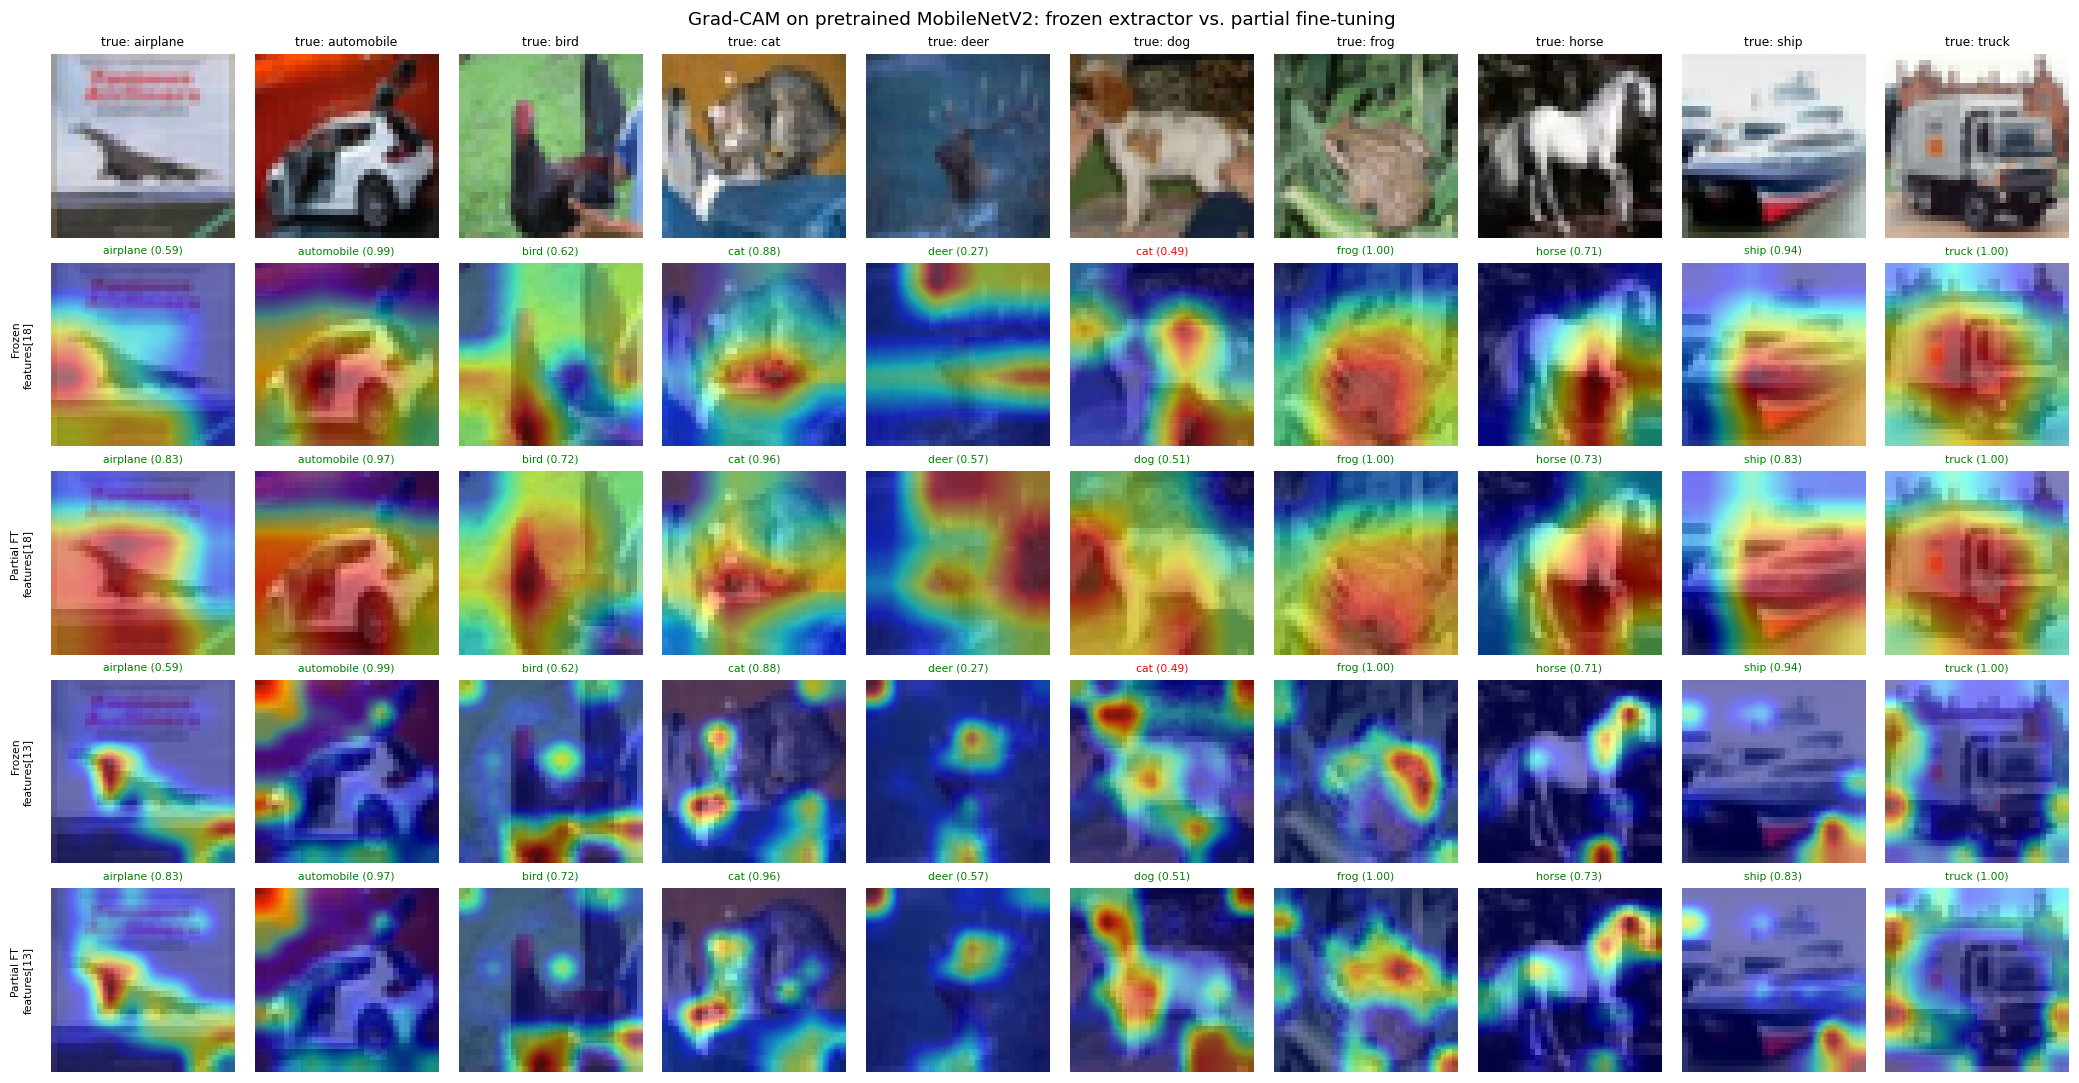

In [ ]:
cam_figure({'Frozen\nfeatures[18]':    (fr_model, fr_model.features[18]),
            'Partial FT\nfeatures[18]': (ft_model, ft_model.features[18]),
            'Frozen\nfeatures[13]':    (fr_model, fr_model.features[13]),
            'Partial FT\nfeatures[13]': (ft_model, ft_model.features[13])},
           X_te, first_per_class, 'Grad-CAM on pretrained MobileNetV2: frozen extractor vs. partial fine-tuning')

### Explaining mistakes
Grad-CAM is most useful for *debugging*: for wrongly classified images we can check whether the model was looking at the object, the background (a "shortcut"), or only a small part.

Partial-FT test errors: 1620 of 10000


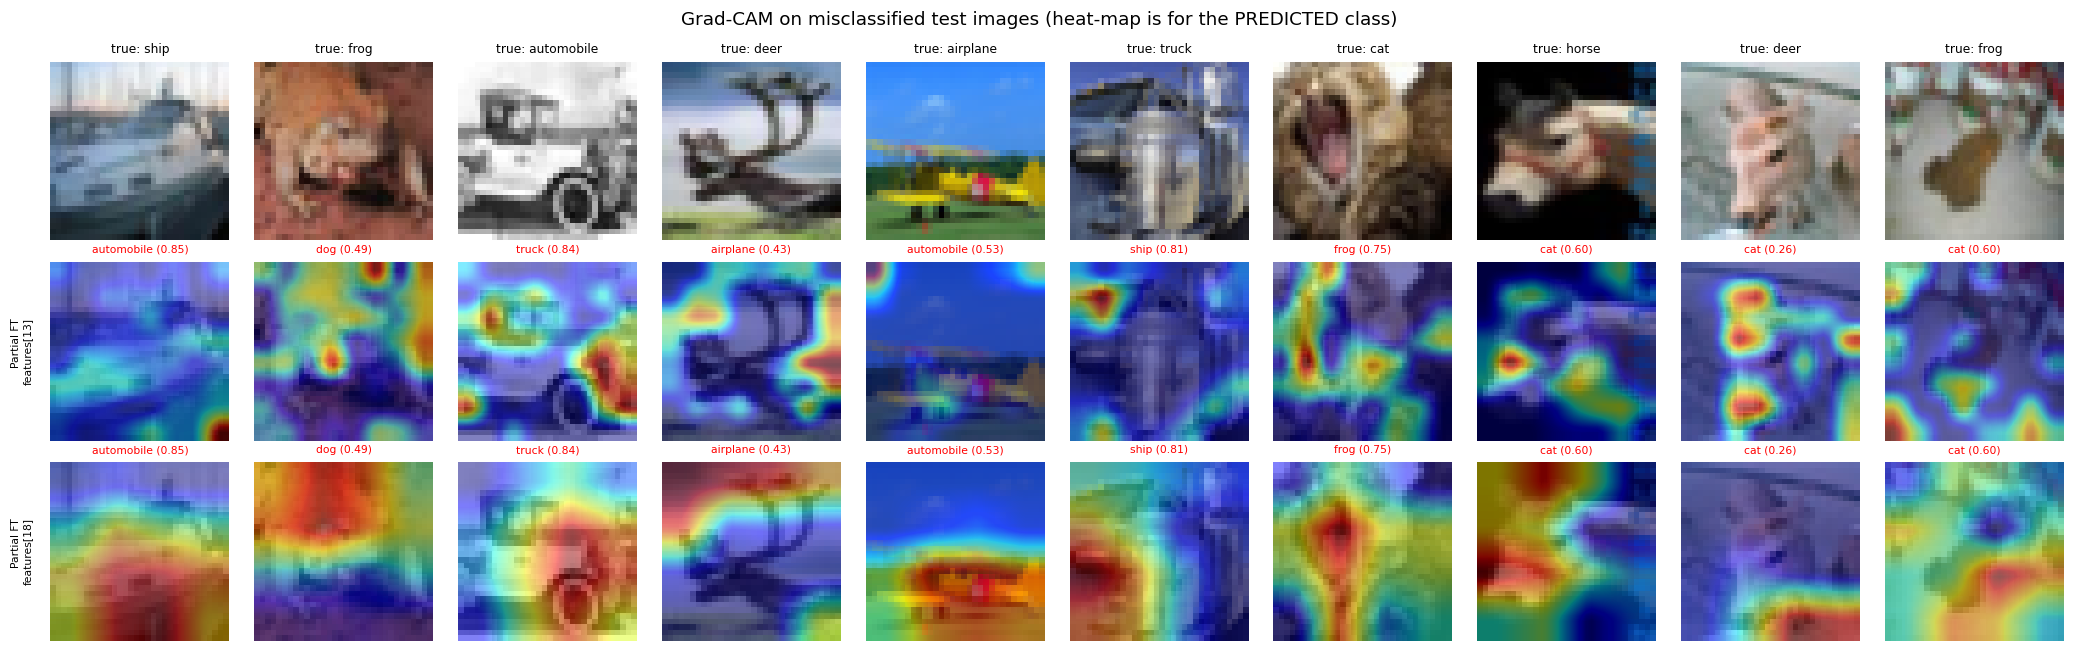

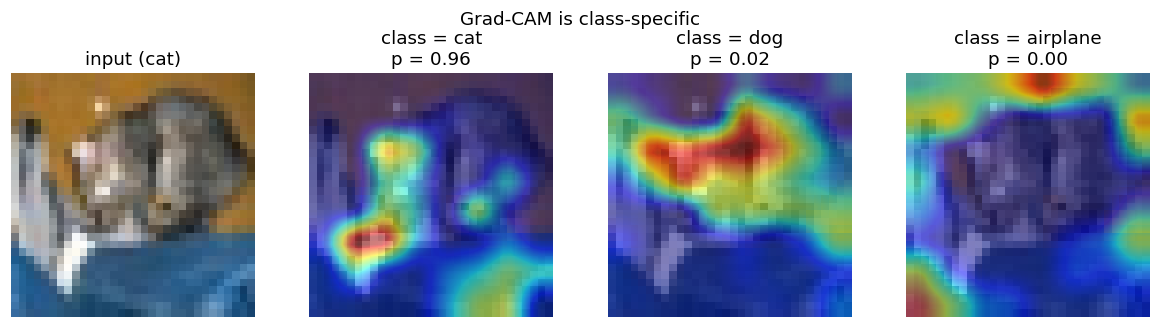

In [ ]:
with torch.no_grad():
    pred_ft = torch.cat([ft_model.eval()(X_te[i:i + 500]).argmax(1) for i in range(0, len(X_te), 500)]).cpu().numpy()
wrong = np.where(pred_ft != y_te_np)[0][:10]
print(f'Partial-FT test errors: {(pred_ft != y_te_np).sum()} of {len(y_te_np)}')
cam_figure({'Partial FT\nfeatures[13]': (ft_model, ft_model.features[13]), 'Partial FT\nfeatures[18]': (ft_model, ft_model.features[18])},
           X_te, wrong, 'Grad-CAM on misclassified test images (heat-map is for the PREDICTED class)')

# Class-specific explanation: same image, CAM for different target classes
i0 = int(first_per_class[CLASSES.index('cat')]); x0 = X_te[i0:i0 + 1]
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
axes[0].imshow(x0[0].permute(1, 2, 0).cpu()); axes[0].set_title('input (cat)'); axes[0].axis('off')
for a, cname in zip(axes[1:], ['cat', 'dog', 'airplane']):
    eng = GradCAM(ft_model, ft_model.features[13]); cam, probs, _ = eng(x0, torch.tensor([CLASSES.index(cname)], device=device)); eng.remove()
    a.imshow(x0[0].permute(1, 2, 0).cpu()); a.imshow(cam[0], cmap='jet', alpha=0.5, interpolation='bilinear')
    a.set_title(f'class = {cname}\np = {probs[0, CLASSES.index(cname)]:.2f}'); a.axis('off')
plt.suptitle('Grad-CAM is class-specific'); plt.tight_layout(); plt.show()

### Observations (Part C)
*Compare with your own figures:*
* **Feature maps:** early maps look like the input with edges/colour regions emphasised; deeper maps are smaller and less recognisable but more class-specific; our scratch ResNet's maps are cleaner at stage 1 than at stage 3.
* **Grad-CAM (correct predictions)** tends to highlight the object (e.g. the ship hull, the horse's body); **fine-tuned** models usually give more focused and class-relevant heat-maps than the frozen extractor, whose evidence is more diffuse because its features were never adapted to CIFAR.
* **Layer choice matters:** `features[18]` is only 4×4 and thus blurry; the intermediate layer gives finer localisation but weaker class specificity.
* **Misclassifications** often show heat-maps on background context or on a part shared by two classes (e.g. cat/dog faces), which suggests what to fix (more augmentation, more data).
* Caveat: Grad-CAM is a *heuristic explanation* of what is sensitive for the score, not proof of causal reasoning.

# Part D: Summary & Conclusions
Fill the table with **your own** results.

| Topic | Key finding (write your result) |
|---|---|
| Plain vs. residual (shallow) | e.g. test acc plain-14 ___ vs residual-14 ___ |
| Plain vs. residual (deep) | e.g. plain-38 ___ vs residual-38 ___ (same parameters: ___) |
| Batch normalization | e.g. removing BN changed deep-residual test acc from ___ to ___ (or diverged) |
| Data augmentation | e.g. without aug: train–val gap ___ and test acc ___ vs ___ with aug |
| Frozen extractor | e.g. test acc ___ with only ___ trainable parameters, ___ s/epoch |
| Partial fine-tuning | e.g. last 2 blocks ___ ; last 5 blocks ___ ; full FT ___ |
| Scratch vs. pretrained | e.g. ___ vs ___ on a 5,000-image subset |
| Feature maps | e.g. edges in early layers → abstract, coarse maps in deep layers |
| Grad-CAM | e.g. heat-maps focus on the object for ___ ; background for misclassified ___ |

### Take-aways
1. **Skip connections** make deep CNNs trainable: the gradient gets an identity path, and the plain/residual comparison at equal parameter count isolates this effect.
2. **BatchNorm** and **augmentation** are cheap, powerful companions: BN stabilises and accelerates optimisation, augmentation reduces overfitting on small data.
3. **Transfer learning** is the most data-efficient route: freeze for speed and tiny parameter budgets; unfreeze the top blocks (with a lower LR) to adapt features; full fine-tuning is rarely needed for small datasets.
4. **Feature maps and Grad-CAM** open the black box: they show the hierarchy of features and let us check *where* a model looks, which helps detect shortcut learning and explain errors.

### Limitations / extensions
* One seed and small subsets → repeat with 3+ seeds and report mean ± std.
* Learning rates were set once, not tuned per method; try a small LR sweep for the backbone.
* Extensions: Grad-CAM++ / Score-CAM, LayerCAM, unfreezing progressively (gradual unfreezing), other lightweight backbones (MobileNetV3, EfficientNet-B0, ShuffleNet), mixup/cutmix augmentation, option-B (1×1 conv) shortcuts.